# Cardiovascular Risk Visualization & Prediction
### INNOTECH 2026
**ML Contributor:** Tooba Ashfaque 
**Dataset:** Extension of Z-Alizadeh Sani Dataset (303 patients, 54+ clinical features)

---
## 1. Environment Setup & Data Ingestion
Extracting the local dataset archive, renaming target columns, and standardizing binary labels.

In [18]:
import os
import glob
import zipfile
import pandas as pd

# 1. Locate dataset (use pre-cleaned CSV if available or locate Excel/Zip)
if os.path.exists('cad_dataset_clean.csv'):
    print("Loading data from existing 'cad_dataset_clean.csv'...")
    df = pd.read_csv('cad_dataset_clean.csv')
else:
    excel_candidates = glob.glob('*.xlsx') + glob.glob('*.xls') + glob.glob('../*.xlsx') + glob.glob('../*.xls')
    if not excel_candidates:
        zip_files = glob.glob('*.zip') + glob.glob('../*.zip')
        if zip_files:
            with zipfile.ZipFile(zip_files[0], 'r') as zip_ref:
                zip_ref.extractall('.')
            excel_candidates = glob.glob('*.xlsx') + glob.glob('*.xls')
    assert len(excel_candidates) > 0, 'No Excel file found!'
    excel_file = excel_candidates[0]
    print(f"Loading data from: {excel_file}")
    df = pd.read_excel(excel_file)
    df.columns = df.columns.str.strip()
    if 'Cath' in df.columns and 'CAD' not in df.columns:
        df['CAD'] = df['Cath']
    target_cols = ['CAD', 'LAD', 'LCX', 'RCA']
    for col in target_cols:
        assert col in df.columns, f"Target '{col}' is missing!"
    df['CAD_binary'] = df['CAD'].astype(str).str.strip().apply(lambda x: 1 if 'cad' in x.lower() else 0)
    for v in ['LAD', 'LCX', 'RCA']:
        df[f'{v}_binary'] = df[v].astype(str).str.strip().apply(lambda x: 1 if 'stenot' in x.lower() else 0)
    df.to_csv('cad_dataset_clean.csv', index=False)
    print(" Successfully created 'cad_dataset_clean.csv'!")

print(f"Total rows: {len(df)}, Total columns: {df.shape[1]}")
print("\n--- Target Class Distributions (1 = Stenotic/Disease, 0 = Normal) ---")
for v in ['CAD_binary', 'LAD_binary', 'LCX_binary', 'RCA_binary']:
    print(f"\n{v}:")
    print(df[v].value_counts(normalize=True).round(3))


Loading data from: extention of Z-Alizadeh sani dataset.xlsx
 Successfully created 'cad_dataset_clean.csv'!
Total rows: 303, Total columns: 64

--- Target Class Distributions (1 = Stenotic/Disease, 0 = Normal) ---

CAD_binary:
CAD_binary
1    0.713
0    0.287
Name: proportion, dtype: float64

LAD_binary:
LAD_binary
1    0.584
0    0.416
Name: proportion, dtype: float64

LCX_binary:
LCX_binary
0    0.607
1    0.393
Name: proportion, dtype: float64

RCA_binary:
RCA_binary
0    0.624
1    0.376
Name: proportion, dtype: float64


In [19]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 64 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    303 non-null    int64  
 1   Weight                 303 non-null    int64  
 2   Length                 303 non-null    int64  
 3   Sex                    303 non-null    object 
 4   BMI                    303 non-null    float64
 5   DM                     303 non-null    int64  
 6   HTN                    303 non-null    int64  
 7   Current Smoker         303 non-null    int64  
 8   EX-Smoker              303 non-null    int64  
 9   FH                     303 non-null    int64  
 10  Obesity                303 non-null    object 
 11  CRF                    303 non-null    object 
 12  CVA                    303 non-null    object 
 13  Airway disease         303 non-null    object 
 14  Thyroid Disease        303 non-null    object 
 15  CHF   

## 2. Preventing Target Leakage & Feature Preprocessing
As mandated by the problem statement:
- Target & leakage features (`Cath`, `CAD`, `LAD`, `LCX`, `RCA`) are stripped from feature matrix $X$.
- Continuous clinical features (Age, Blood Pressure, Cholesterol, EF) are normalized using `StandardScaler`.
- Categorical features (ECG markers, pain symptoms, demographics) are transformed using `OneHotEncoder`.

In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# Check if xgboost is installed, else use RandomForest
try:
    from xgboost import XGBClassifier
    base_model = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss')
    print("Using XGBoost Classifier")
except ImportError:
    base_model = RandomForestClassifier(n_estimators=150, max_depth=5, random_state=42)
    print("XGBoost not found, using RandomForestClassifier")

# 1. Define Leakage and Target Columns to exclude from input X
leakage_and_target_cols = [
    'Cath', 'CAD', 'LAD', 'LCX', 'RCA',
    'CAD_binary', 'LAD_binary', 'LCX_binary', 'RCA_binary'
]

# Separate feature matrix X and targets Y
feature_cols = [col for col in df.columns if col not in leakage_and_target_cols]
X = df[feature_cols].copy()

targets = {
    'CAD': df['CAD_binary'],
    'LAD': df['LAD_binary'],
    'LCX': df['LCX_binary'],
    'RCA': df['RCA_binary']
}

print(f"Features count (without leakage): {X.shape[1]}")

# 2. Identify Numeric vs Categorical features
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Ensure string cleanup for categorical columns
for col in categorical_cols:
    X[col] = X[col].astype(str).str.strip().str.title()

# 3. Create Preprocessor Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit-transform features
X_processed = preprocessor.fit_transform(X)
feature_names_out = (
    numerical_cols + 
    preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
)

print(f"Total processed feature dimensions: {X_processed.shape[1]}")

Using XGBoost Classifier
Features count (without leakage): 55
Total processed feature dimensions: 78


## 3. Multi-Target Classification with XGBoost
Training 4 separate gradient boosted classifiers to predict:
1. Overall CAD Status
2. LAD Stenosis
3. LCX Stenosis
4. RCA Stenosis

Models are evaluated using Stratified 5-Fold / 80-20 Train-Test split on Accuracy, F1-Score, and ROC-AUC.

In [21]:
models = {}
eval_results = {}

print("--- Training Models with Algorithmic Class Weighting (scale_pos_weight) ---")
for target_name, y in targets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X_processed, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Calculate algorithmic class weighting: neg_count / pos_count
    pos_count = int((y_train == 1).sum())
    neg_count = int((y_train == 0).sum())
    weight = float(neg_count) / float(pos_count)
    
    # Initialize model with class weighting to fix class imbalance
    if 'XGBClassifier' in str(type(base_model)):
        clf = XGBClassifier(
            n_estimators=120, 
            max_depth=3, 
            learning_rate=0.08, 
            scale_pos_weight=weight,    # <-- Algorithmic class weighting
            random_state=42, 
            eval_metric='logloss'
        )
    else:
        clf = RandomForestClassifier(
            n_estimators=150, 
            max_depth=5, 
            class_weight='balanced',    # <-- For Random Forest
            random_state=42
        )
        
    clf.fit(X_train, y_train)
    
    # Predictions and Probabilities
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    models[target_name] = clf
    eval_results[target_name] = {
        'Class Weight': round(weight, 3),
        'Accuracy': round(acc, 3),
        'F1-Score': round(f1, 3),
        'ROC-AUC': round(auc, 3)
    }
    
    print(f"Target: {target_name:4} | Weight: {weight:.3f} | Accuracy: {acc:.3f} | F1: {f1:.3f} | ROC-AUC: {auc:.3f}")

# Display summary table for your presentation deck
metrics_df = pd.DataFrame(eval_results).T
print("\n--- Summary Evaluation Metrics with Class Weighting ---")
print(metrics_df.round(3))


--- Training Models with Algorithmic Class Weighting (scale_pos_weight) ---
Target: CAD  | Weight: 0.399 | Accuracy: 0.836 | F1: 0.886 | ROC-AUC: 0.837
Target: LAD  | Weight: 0.716 | Accuracy: 0.754 | F1: 0.795 | ROC-AUC: 0.823
Target: LCX  | Weight: 1.547 | Accuracy: 0.705 | F1: 0.609 | ROC-AUC: 0.745
Target: RCA  | Weight: 1.659 | Accuracy: 0.738 | F1: 0.636 | ROC-AUC: 0.792

--- Summary Evaluation Metrics with Class Weighting ---
     Class Weight  Accuracy  F1-Score  ROC-AUC
CAD         0.399     0.836     0.886    0.837
LAD         0.716     0.754     0.795    0.823
LCX         1.547     0.705     0.609    0.745
RCA         1.659     0.738     0.636    0.792


## 4. Calibrated Vessel Risk Probability Generation
Generating continuous risk probabilities ($0.0 \to 1.0$) for LAD, LCX, and RCA to dynamically map color gradients (Green $\to$ Amber $\to$ Red) onto the 3D heart mesh.

In [22]:
# Test prediction on a single patient record (e.g., patient index 0)
sample_patient = X_processed[0:1]

sample_prediction = {
    "overall_cad_risk": round(float(models['CAD'].predict_proba(sample_patient)[0, 1]), 3),
    "vessel_stenosis_risks": {
        "LAD": round(float(models['LAD'].predict_proba(sample_patient)[0, 1]), 3),
        "LCX": round(float(models['LCX'].predict_proba(sample_patient)[0, 1]), 3),
        "RCA": round(float(models['RCA'].predict_proba(sample_patient)[0, 1]), 3),
    }
}

print("\n--- Sample Output for Antigravity Frontend & 3D Viewer ---")
print(sample_prediction)


--- Sample Output for Antigravity Frontend & 3D Viewer ---
{'overall_cad_risk': 0.838, 'vessel_stenosis_risks': {'LAD': 0.264, 'LCX': 0.082, 'RCA': 0.066}}


## 5. Clinical Explainability (SHAP TreeExplainer)
Extracting global and localized feature attributions to provide clinicians with transparent, interpretable reasons for predicted stenosis risks.

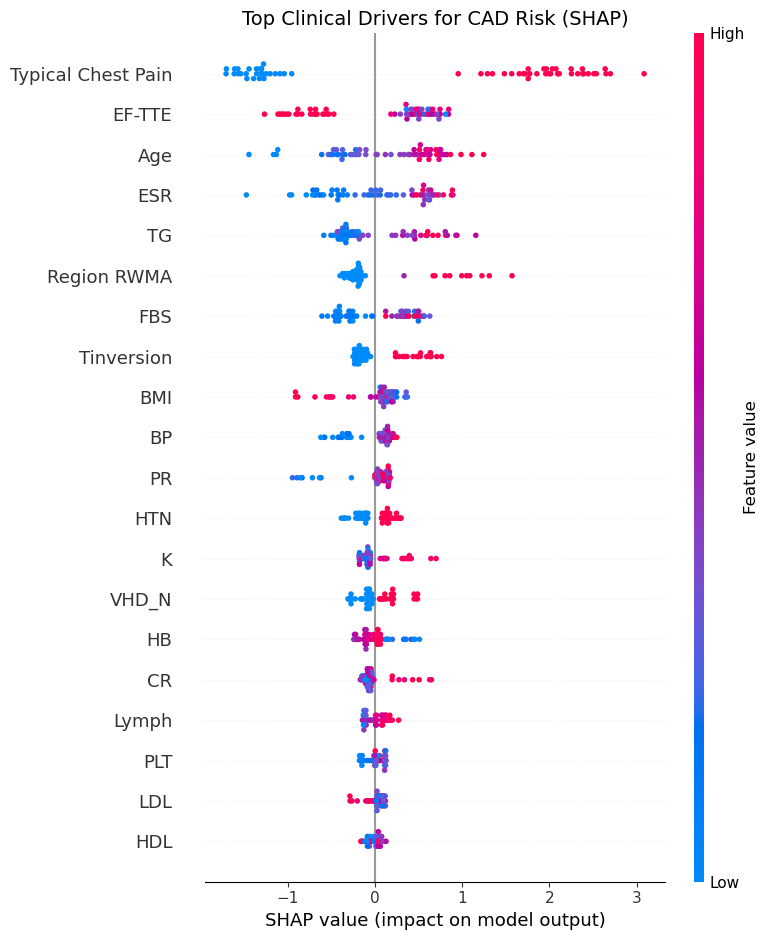

Saved 'shap_global_summary.png' for presentation deck!


In [23]:
!pip install shap matplotlib

import shap
import matplotlib.pyplot as plt

# 1. Initialize TreeExplainer for the CAD model
explainer = shap.TreeExplainer(models['CAD'])
shap_values = explainer.shap_values(X_test)

# 2. Plot Global Feature Importance (Save this image for your presentation slides!)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=feature_names_out, show=False)
plt.title("Top Clinical Drivers for CAD Risk (SHAP)", fontsize=14)
plt.tight_layout()
plt.savefig("shap_global_summary.png", dpi=200)
plt.show()
print("Saved 'shap_global_summary.png' for presentation deck!")

In [24]:
def explain_patient(patient_vector, top_n=5):
    """
    Computes local SHAP attribution for a single patient record
    and returns top features that increase or reduce cardiac risk.
    """
    sv = explainer.shap_values(patient_vector)[0]
    
    # Pair feature names with their shap impact
    factors = []
    for name, impact in zip(feature_names_out, sv):
        factors.append({
            "feature": name,
            "impact": float(impact),
            "effect": "Increases Risk" if impact > 0 else "Lowers Risk"
        })
    
    # Sort by absolute impact magnitude
    factors.sort(key=lambda x: abs(x["impact"]), reverse=True)
    return factors[:top_n]

# Test on patient 0
sample_explanations = explain_patient(sample_patient)
print("--- Sample SHAP Explanation for Dashboard ---")
for item in sample_explanations:
    print(f"• {item['feature']}: {item['effect']} (SHAP value: {item['impact']:+.3f})")

--- Sample SHAP Explanation for Dashboard ---
• Typical Chest Pain: Lowers Risk (SHAP value: -1.143)
• EF-TTE: Increases Risk (SHAP value: +0.746)
• TG: Increases Risk (SHAP value: +0.723)
• K: Increases Risk (SHAP value: +0.641)
• Tinversion: Increases Risk (SHAP value: +0.496)


## 6. Pipeline Serialization for Deployment
Exporting preprocessor transformers and trained model weights into `cardio_models.joblib` for direct integration with the FastAPI / Antigravity service layer.

In [25]:
import joblib

# Export preprocessor, feature names, and all 4 trained models
payload = {
    "preprocessor": preprocessor,
    "feature_names_raw": feature_cols,
    "feature_names_processed": feature_names_out,
    "models": models
}

joblib.dump(payload, "cardio_models.joblib")
print(" Successfully exported 'cardio_models.joblib'!")

 Successfully exported 'cardio_models.joblib'!


## re export pipelines
creating pipeline objects for each target and exporting them

In [26]:
import joblib
from sklearn.pipeline import Pipeline
import shap

# 1. Build an end-to-end Pipeline for each target
pipelines = {}
for target_name in ['CAD', 'LAD', 'LCX', 'RCA']:
    pipelines[target_name] = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', models[target_name])
    ])

# 2. Fit SHAP Explainer
explainer = shap.TreeExplainer(models['CAD'])

# 3. Export bundle with BOTH 'models' and 'pipelines' keys for complete safety
export_bundle = {
    'pipelines': pipelines,
    'models': models,               # <-- Fixes KeyError: 'models'
    'preprocessor': preprocessor,
    'feature_names_raw': feature_cols,
    'raw_feature_names': feature_cols,
    'feature_names_processed': feature_names_out,
    'processed_feature_names': feature_names_out,
    'explainer': explainer
}

joblib.dump(export_bundle, 'cardio_models.joblib')
print("✅ cardio_models.joblib re-exported successfully with universal dictionary keys!")

✅ cardio_models.joblib re-exported successfully with universal dictionary keys!


## 7. Representative Clinical Personas for Live Demonstration
Extracting three ground-truth patient profiles directly from the dataset (`Low Risk / Normal`, `Isolated LAD Stenosis`, and `Multi-Vessel High Risk CAD`) with schema-verified types (`demo_presets.json`) for one-click frontend simulation.

In [27]:
import json

# Compute predictions across all rows of X to pick 3 real representative patients
all_probs = pd.DataFrame({
    'CAD': models['CAD'].predict_proba(X_processed)[:, 1],
    'LAD': models['LAD'].predict_proba(X_processed)[:, 1],
    'LCX': models['LCX'].predict_proba(X_processed)[:, 1],
    'RCA': models['RCA'].predict_proba(X_processed)[:, 1]
})

# Pick 3 distinct real patients by their true row index in X
low_idx = all_probs[(all_probs['CAD'] < 0.15) & (all_probs['LAD'] < 0.15)].index[0]
lad_idx = all_probs[(all_probs['LAD'] > 0.75) & (all_probs['LCX'] < 0.25) & (all_probs['RCA'] < 0.25)].index[0]
multi_idx = all_probs[(all_probs['CAD'] > 0.90) & (all_probs['LAD'] > 0.80) & (all_probs['RCA'] > 0.70)].index[0]

demo_presets = {
    "Patient 1 - Healthy / Low Risk": {
        "expected_output": all_probs.loc[low_idx].round(3).to_dict(),
        "patient_data": X.loc[low_idx].to_dict()
    },
    "Patient 2 - Single-Vessel (LAD) Stenosis": {
        "expected_output": all_probs.loc[lad_idx].round(3).to_dict(),
        "patient_data": X.loc[lad_idx].to_dict()
    },
    "Patient 3 - Severe Multi-Vessel CAD": {
        "expected_output": all_probs.loc[multi_idx].round(3).to_dict(),
        "patient_data": X.loc[multi_idx].to_dict()
    }
}

with open("demo_presets.json", "w") as f:
    json.dump(demo_presets, f, indent=2)

print("✅ Saved 'demo_presets.json' directly from dataset schema!")
for name, data in demo_presets.items():
    print(f"• {name} -> {data['expected_output']}")

✅ Saved 'demo_presets.json' directly from dataset schema!
• Patient 1 - Healthy / Low Risk -> {'CAD': 0.09399999678134918, 'LAD': 0.10400000214576721, 'LCX': 0.09099999815225601, 'RCA': 0.20200000703334808}
• Patient 2 - Single-Vessel (LAD) Stenosis -> {'CAD': 0.9980000257492065, 'LAD': 0.9190000295639038, 'LCX': 0.10999999940395355, 'RCA': 0.06599999964237213}
• Patient 3 - Severe Multi-Vessel CAD -> {'CAD': 0.9819999933242798, 'LAD': 0.8579999804496765, 'LCX': 0.42100000381469727, 'RCA': 0.7699999809265137}


## 8. FastAPI Backend Service Generation (`server.py`)
Generating the standalone production FastAPI script (`server.py`) that loads `cardio_models.joblib` and exposes the `POST /predict` endpoint for the Antigravity frontend and 3D visualization canvas.


In [28]:
%%writefile server.py
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(
    title="CardioRisk 3D Prediction & Explainability API",
    description="Track A Backend Service",
    version="1.0.0"
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# Load the saved bundle containing end-to-end pipelines and preprocessor
print("Loading model pipelines and explainer...")
bundle = joblib.load("cardio_models.joblib")
pipelines = bundle["pipelines"]
preprocessor = bundle["preprocessor"]
explainer = bundle["explainer"]
raw_feature_names = bundle["raw_feature_names"]
processed_feature_names = bundle["processed_feature_names"]
print("All pipelines loaded successfully!")

@app.get("/")
def health_check():
    return {"status": "healthy", "service": "CardioRisk Inference Engine"}

@app.post("/predict")
def predict_patient(patient_data: dict):
    try:
        # Convert dictionary to DataFrame
        df_in = pd.DataFrame([patient_data])
        
        # Ensure exact column presence and order as seen during training
        for col in raw_feature_names:
            if col not in df_in.columns:
                df_in[col] = None
        df_in = df_in[raw_feature_names]
        
        # Clean string values (title case and whitespace stripping) to match training categories
        cat_cols = df_in.select_dtypes(include=['object']).columns
        for c in cat_cols:
            df_in[c] = df_in[c].astype(str).str.strip().str.title()

        # Run inference directly through each pipeline
        cad_risk = float(pipelines["CAD"].predict_proba(df_in)[0, 1])
        lad_risk = float(pipelines["LAD"].predict_proba(df_in)[0, 1])
        lcx_risk = float(pipelines["LCX"].predict_proba(df_in)[0, 1])
        rca_risk = float(pipelines["RCA"].predict_proba(df_in)[0, 1])

        # Compute local SHAP attributions for clinical interpretability
        X_proc = preprocessor.transform(df_in)
        shap_vals = explainer.shap_values(X_proc)
        
        # Account for binary classification SHAP shapes
        if isinstance(shap_vals, list):
            sv = shap_vals[1][0] if len(shap_vals) > 1 else shap_vals[0][0]
        elif hasattr(shap_vals, "shape") and len(shap_vals.shape) == 3:
            sv = shap_vals[0, :, 1]
        elif hasattr(shap_vals, "shape") and len(shap_vals.shape) == 2:
            sv = shap_vals[0]
        else:
            sv = np.array(shap_vals).flatten()
            
        explanations = []
        for name, imp in zip(processed_feature_names, sv):
            explanations.append({
                "feature": str(name),
                "impact": round(float(imp), 3),
                "effect": "Increases Risk" if float(imp) > 0 else "Lowers Risk"
            })
        explanations.sort(key=lambda x: abs(x["impact"]), reverse=True)

        return {
            "overall_cad_risk": round(cad_risk, 3),
            "vessels": {
                "LAD": round(lad_risk, 3),
                "LCX": round(lcx_risk, 3),
                "RCA": round(rca_risk, 3)
            },
            "top_factors": explanations[:5],
            "disclaimer": "Predictions are for clinical decision support / educational purposes only and not a substitute for formal diagnostic imaging."
        }

    except Exception as e:
        import traceback
        traceback.print_exc()
        raise HTTPException(status_code=500, detail=str(e))

Overwriting server.py
